# Лабораторная работа 4. Кластеризация
Курбатов М. П., группа 4417. Вариант 13.

Цель: изучить K-means и агломеративную кластеризацию, подобрать число кластеров и оценить результат. Работа следует двум частям методички 2026 года (страницы 17–23).

Для части 2 принято циклическое соответствие вариантов: (13 − 1) % 5 + 1 = 3, ecommerce_fraud.csv. Методичка перечисляет пять вариантов, но не устанавливает правило для номера 13; соответствие следует уточнить у преподавателя.

Загрузите CSV в Colab и при необходимости измените file_path ниже. Импорты и чтение файла выполняются один раз.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             adjusted_mutual_info_score)
from sklearn.metrics.cluster import contingency_matrix
from scipy.cluster.hierarchy import linkage, dendrogram

file_path = '/content/ecommerce_fraud.csv'
RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

def cluster_metrics(X, labels, truth=None):
    result = {'Silhouette': silhouette_score(X, labels),
              'Calinski_Harabasz': calinski_harabasz_score(X, labels),
              'Davies_Bouldin': davies_bouldin_score(X, labels)}
    if truth is not None:
        result['ARI'] = adjusted_rand_score(truth, labels)
        result['AMI'] = adjusted_mutual_info_score(truth, labels)
    return result

## Часть 1. Искусственные данные
### 1–3. Создание и стандартизация
Использую функцию из методички без изменения логики: три группы по n = 100 объектов, seed = 42. Всего 300 строк. Множители 20 и 0,5 создают разные масштабы координат. StandardScaler преобразует каждый признак: z = (x − среднее) / стандартное отклонение (ddof = 0).

In [2]:
def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]}, columns=['x', 'y'])
    df = df.sample(frac=1.0)
    return df

synthetic = make_data(n=100, seed=RANDOM_STATE)
synthetic_scaler = StandardScaler()
synthetic_scaled = synthetic_scaler.fit_transform(synthetic)
print('Размер:', synthetic.shape)
display(synthetic.head())
display(pd.DataFrame({'Среднее z': synthetic_scaled.mean(axis=0),
                      'Стандартное отклонение z': synthetic_scaled.std(axis=0)},
                     index=synthetic.columns))

Размер: (300, 2)


,x,y
79,20.248622,2.860085
12,64.839245,1.530115
204,170.998691,1.174679
137,123.729086,4.339307
99,55.308257,0.928515


,Среднее z,Стандартное отклонение z
x,-1.717145e-16,1.0
y,2.368476e-17,1.0


### 4–7. K-means для 3, 2 и 4 кластеров
Обучаю через fit_predict на стандартизованных данных. Центры перевожу обратно inverse_transform и показываю на исходных осях. Цвет означает номер кластера, крест — центр. Номер кластера не является классом и не имеет собственного порядка. Силуэт s = (b − a) / max(a, b); ближе к 1 — лучше разделение, около 0 — перекрытие.

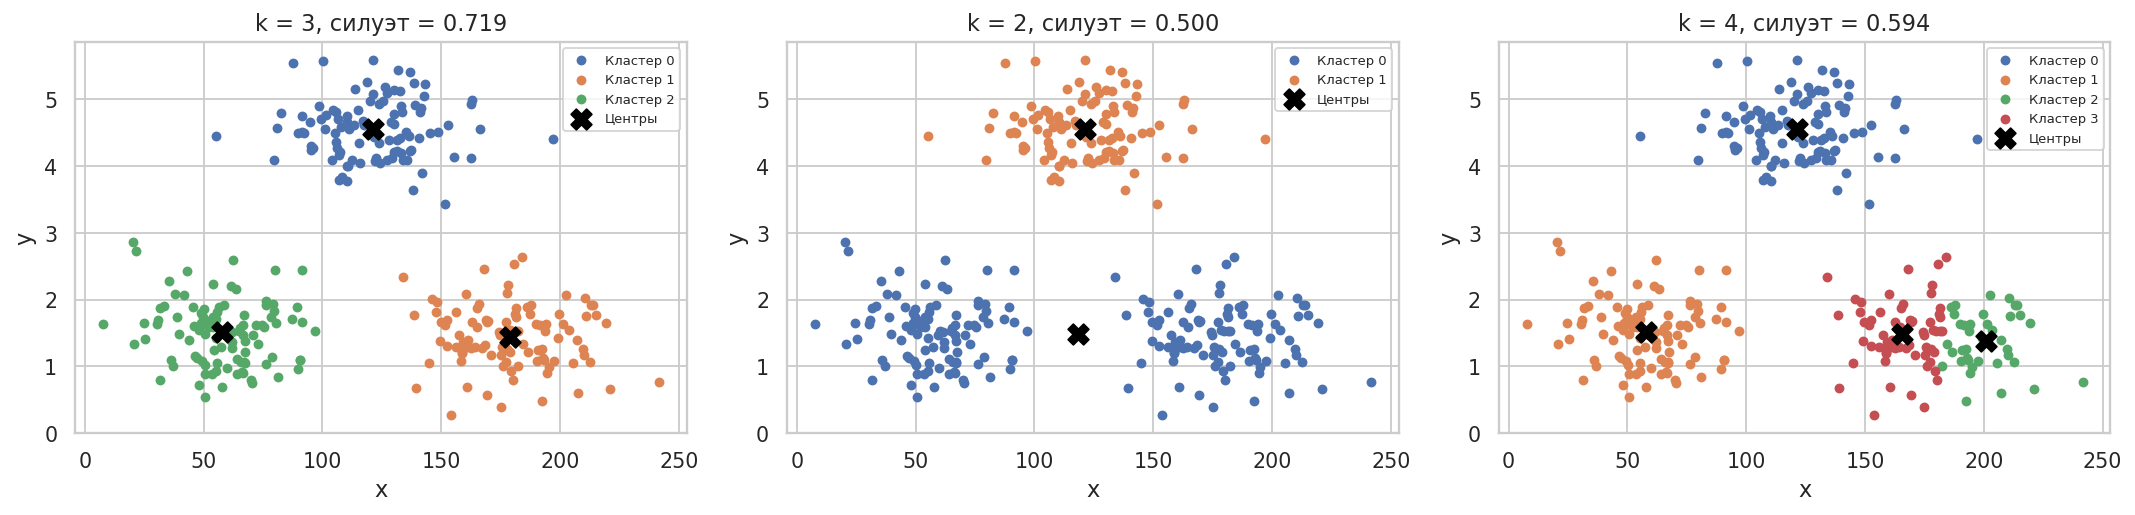

,k,Silhouette,Inertia
1,2,0.4997,327.1143
0,3,0.7186,70.6693
2,4,0.5938,60.3187


In [3]:
synthetic_models = {}
synthetic_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, k in zip(axes, [3, 2, 4]):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = model.fit_predict(synthetic_scaled)
    synthetic_models[k] = model
    centers = synthetic_scaler.inverse_transform(model.cluster_centers_)
    for cluster in range(k):
        points = synthetic.loc[labels == cluster]
        ax.scatter(points['x'], points['y'], s=18, label=f'Кластер {cluster}')
    ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='X',
               s=120, label='Центры')
    score = silhouette_score(synthetic_scaled, labels)
    synthetic_rows.append({'k': k, 'Silhouette': score, 'Inertia': model.inertia_})
    ax.set(title=f'k = {k}, силуэт = {score:.3f}', xlabel='x', ylabel='y')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
synthetic_results = pd.DataFrame(synthetic_rows).sort_values('k')
display(synthetic_results.round(4))

### 8. Метод локтя
Inertia — сумма квадратов расстояний до ближайших центров в стандартизованном пространстве. Она убывает при увеличении k; оцениваю изменение наклона, а не минимум инерции. Сопоставляю локоть с силуэтом и известной конструкцией из трёх групп.

Лучший силуэт среди k=2,3,4: 3


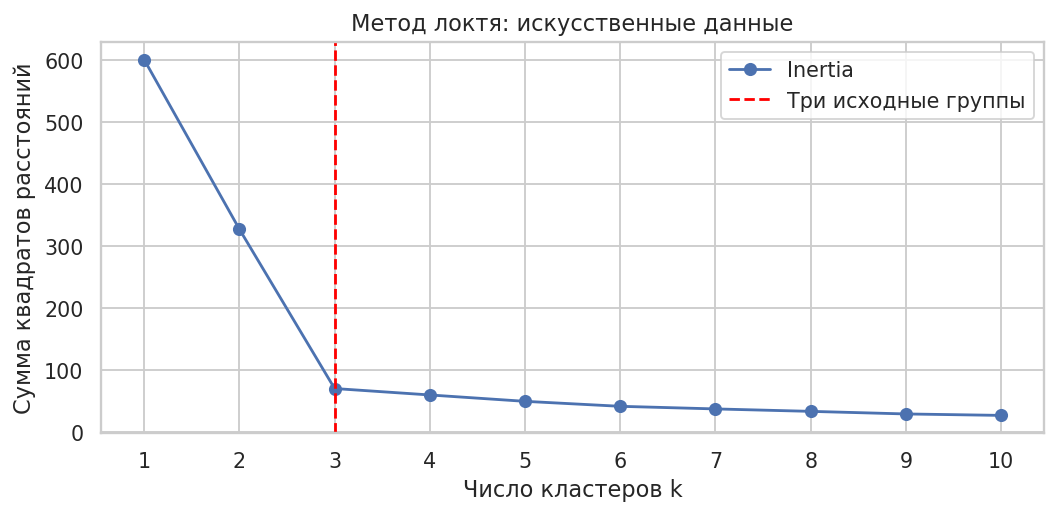

In [4]:
elbow_rows = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    model.fit(synthetic_scaled)
    elbow_rows.append({'k': k, 'Inertia': model.inertia_})
elbow_synthetic = pd.DataFrame(elbow_rows)
plt.figure(figsize=(8, 4))
plt.plot(elbow_synthetic['k'], elbow_synthetic['Inertia'], 'o-', label='Inertia')
plt.axvline(3, color='red', linestyle='--', label='Три исходные группы')
plt.xlabel('Число кластеров k')
plt.ylabel('Сумма квадратов расстояний')
plt.title('Метод локтя: искусственные данные')
plt.xticks(range(1, 11))
plt.legend()
plt.tight_layout()
plt.show()
print('Лучший силуэт среди k=2,3,4:',
      int(synthetic_results.loc[synthetic_results['Silhouette'].idxmax(), 'k']))

## Часть 2. Транзакции интернет-магазина
### 1. Загрузка и описание
ecommerce_fraud.csv: сумма покупки transaction_amount (USD), количество товаров num_items, время на сайте time_on_site_sec (секунды), час hour_of_day, возраст аккаунта account_age_days (дни); категории device_type, browser, payment_method, country, is_first_purchase, referral. Fraud: 1 — мошенническая, 0 — обычная транзакция.

Кластеризация не обучается предсказывать Fraud: метка используется только для раскраски и внешних метрик. Разделение train/test для описательной кластеризации данного набора не требуется; полученные оценки не являются качеством прогноза на новых транзакциях.

In [5]:
raw = pd.read_csv(file_path)
print('Исходный размер:', raw.shape)
display(raw.head(10))
raw.info()
display(raw.describe(include='all'))
print('Пропуски:', raw.isna().sum().to_dict())
print('Полные дубликаты:', raw.duplicated().sum())
display(raw['Fraud'].value_counts().rename('Количество').to_frame())

Исходный размер: (3024, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3024 entries, 0 to 3023
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_amount  3024 non-null   float64
 1   device_type         3024 non-null   object 
 2   browser             3024 non-null   object 
 3   payment_method      3024 non-null   object 
 4   country             3024 non-null   object 
 5   num_items           3024 non-null   int64  
 6   time_on_site_sec    3024 non-null   float64
 7   is_first_purchase   3024 non-null   object 
 8   referral            3024 non-null   object 
 9   hour_of_day         3024 non-null   int64  
 10  account_age_days    3024 non-null   int64  
 11  Fraud               3024 non-null   int64  
dtypes: float64(2), int64(4), object(6)
memory usage: 283.6+ KB
Пропуски: {'transaction_amount': 0, 'device_type': 0, 'browser': 0, 'payment_method': 0, 'country': 0, 'num_items':

,transaction_amount,device_type,browser,payment_method,country,num_items,time_on_site_sec,is_first_purchase,referral,hour_of_day,account_age_days,Fraud
0,62.18,Desktop,Safari,COD,UK,3,58.0,No,Direct,15,808,0
1,28.16,Desktop,Chrome,COD,US,2,75.0,Yes,Direct,10,753,0
2,17.57,Mobile,Chrome,Card,DE,1,101.0,No,Social,21,1017,0
3,61.61,Desktop,Safari,PayPal,Other,4,63.0,Yes,Search,20,1146,0
4,4.28,Desktop,Edge,Card,BR,7,399.0,No,Direct,4,1134,0
5,1.85,Desktop,Firefox,Card,IN,5,307.0,Yes,Search,23,674,0
6,12.50,Mobile,Chrome,PayPal,US,4,381.0,No,Search,2,1712,0
7,35.30,Desktop,Safari,Card,IN,3,98.0,No,Search,6,1370,0
8,81.59,Mobile,Firefox,Card,FR,1,257.0,Yes,Direct,17,1574,0
9,46.25,Mobile,Chrome,BankTransfer,IN,5,137.0,No,Search,3,224,0


,transaction_amount,device_type,browser,payment_method,country,num_items,time_on_site_sec,is_first_purchase,referral,hour_of_day,account_age_days,Fraud
count,3024.000000,3024,3024,3024,3024,3024.000000,3024.000000,3024,3024,3024.000000,3024.000000,3024.000000
unique,NaN,3,5,4,8,NaN,NaN,2,4,NaN,NaN,NaN
top,NaN,Mobile,Chrome,Card,US,NaN,NaN,No,Search,NaN,NaN,NaN
freq,NaN,1439,1491,1832,984,NaN,NaN,1778,1326,NaN,NaN,NaN
mean,84.492933,NaN,NaN,NaN,NaN,4.034722,163.180688,NaN,NaN,11.383929,922.302579,0.044643
std,126.090008,NaN,NaN,NaN,NaN,1.983504,113.971918,NaN,NaN,6.916191,529.453654,0.206553
min,-7.400000,NaN,NaN,NaN,NaN,1.000000,-150.000000,NaN,NaN,0.000000,2.000000,0.000000
25%,17.615000,NaN,NaN,NaN,NaN,2.000000,82.000000,NaN,NaN,5.000000,459.000000,0.000000
50%,45.370000,NaN,NaN,NaN,NaN,4.000000,141.000000,NaN,NaN,12.000000,934.500000,0.000000
75%,99.937500,NaN,NaN,NaN,NaN,6.000000,218.250000,NaN,NaN,17.000000,1380.250000,0.000000


,Количество
Fraud,
0,2889
1,135


### 2. Предварительная обработка
Удаляю полные дубликаты, проверяю типы и допустимые интервалы. Отрицательные сумма покупки и длительность сеанса здесь недопустимы: заменяю такие значения на NaN, затем заполняю медианой соответствующего признака. Категориальные пропуски при наличии заполняю Unknown. Не удаляю редкий класс и не фильтрую строки по Fraud.

Крупные положительные суммы сами по себе не считаю ошибками: методичка прямо указывает логнормальное распределение. Для суммы и времени применяю log1p, чтобы уменьшить влияние длинных хвостов на расстояния, затем стандартизую числовые признаки. Исходные единицы остаются в таблицах профилей. Все изменения и их количество выводятся ниже.

In [6]:
data = raw.drop_duplicates().copy()
numeric_columns = ['transaction_amount', 'num_items', 'time_on_site_sec',
                   'hour_of_day', 'account_age_days']
category_columns = ['device_type', 'browser', 'payment_method', 'country',
                    'is_first_purchase', 'referral']
for column in category_columns:
    data[column] = data[column].astype('string').str.strip().fillna('Unknown')
repairs = []
for column in numeric_columns:
    values = pd.to_numeric(data[column], errors='coerce')
    invalid = values < 0
    if column == 'num_items':
        invalid |= (values < 1) | (values > 7) | (values % 1 != 0)
    if column == 'hour_of_day':
        invalid |= (values > 23) | (values % 1 != 0)
    values = values.mask(invalid)
    missing = int(values.isna().sum())
    median = values.median()
    if pd.isna(median):
        raise ValueError(f'В {column} нет допустимых числовых значений')
    data[column] = values.fillna(median)
    repairs.append({'Признак': column, 'Исправлено': missing, 'Медиана': median})
assert data['Fraud'].isin([0, 1]).all()
assert not data[numeric_columns + category_columns].isna().any().any()
print('Удалено полных дубликатов:', len(raw) - len(data))
display(pd.DataFrame(repairs))
print('Строк после обработки:', len(data))

Удалено полных дубликатов: 0
Строк после обработки: 3024


,Признак,Исправлено,Медиана
0,transaction_amount,130,48.335
1,num_items,0,4.000
2,time_on_site_sec,24,142.000
3,hour_of_day,0,12.000
4,account_age_days,0,934.500


### 3. Целевая метка и матрица диаграмм рассеяния
Строю pairplot по всем пяти числовым признакам на всех очищенных строках; цвет задаёт Fraud. По диагонали гистограммы, вне диагонали пары признаков. Редкие красные точки — не автоматически выбросы. Признак Fraud не включён в матрицу X. Перекрытие цветов показывает, что классы не обязательно образуют отдельные компактные кластеры.

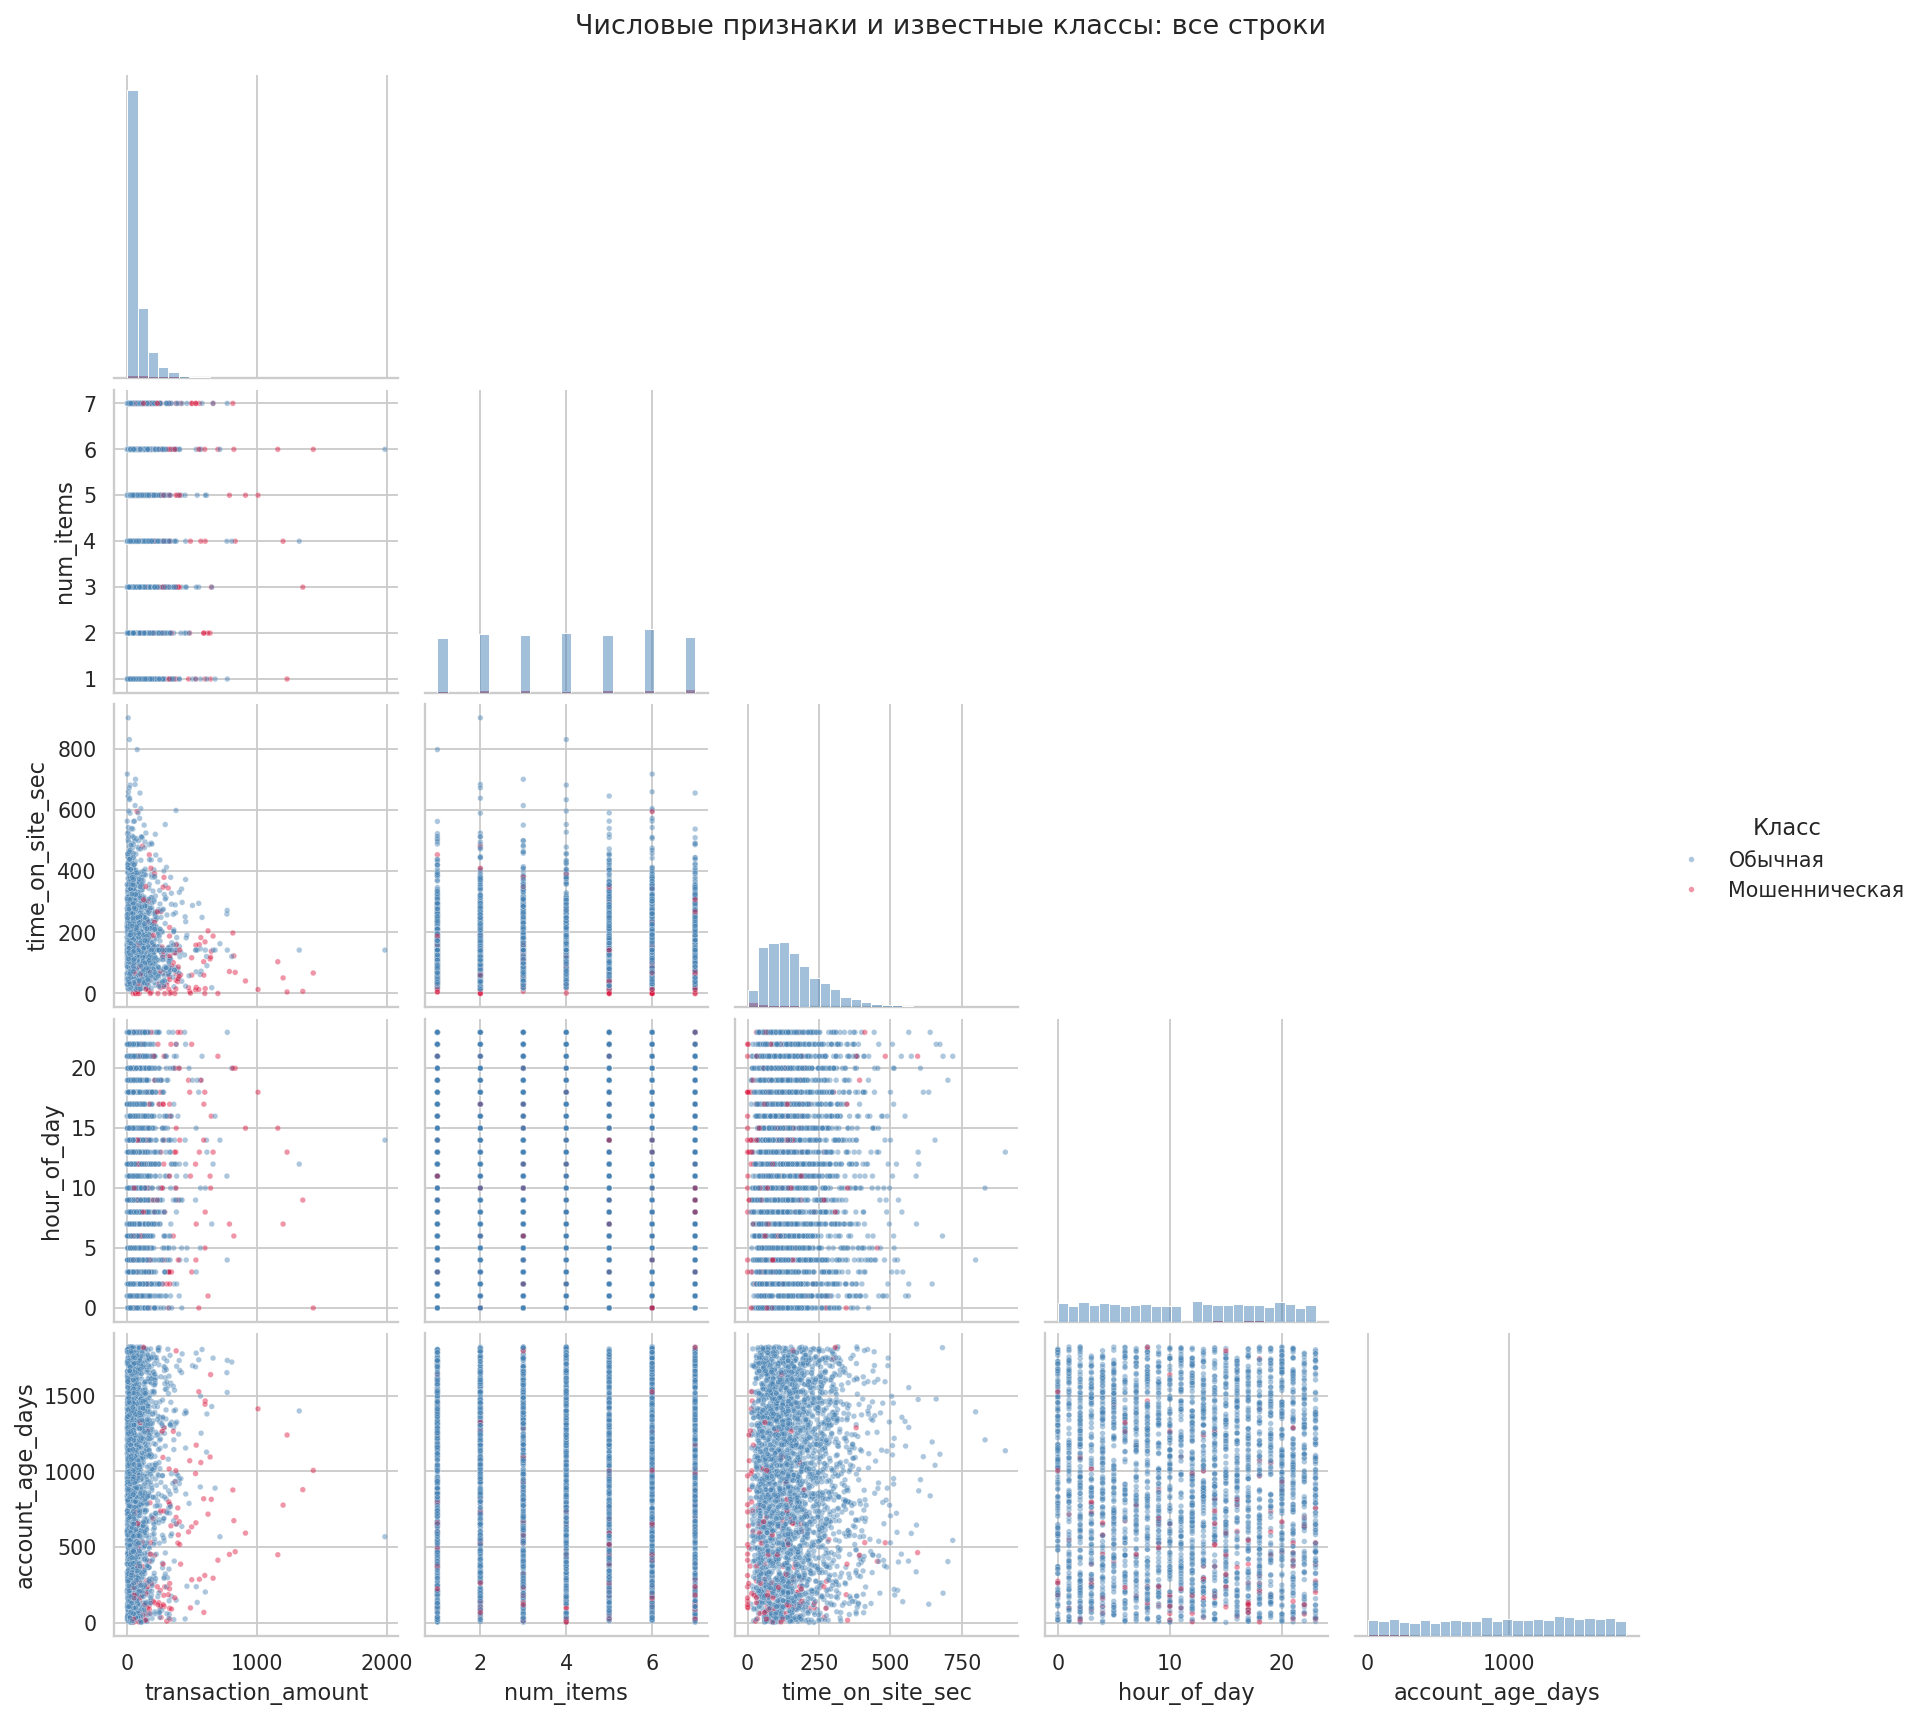

In [7]:
y = data['Fraud'].astype(int).copy()
pair_data = data[numeric_columns].copy()
pair_data['Класс'] = y.map({0: 'Обычная', 1: 'Мошенническая'})
grid = sns.pairplot(pair_data, vars=numeric_columns, hue='Класс',
                    diag_kind='hist', corner=True,
                    palette={'Обычная': 'steelblue', 'Мошенническая': 'crimson'},
                    plot_kws={'s': 9, 'alpha': 0.45},
                    diag_kws={'bins': 25})
grid.fig.suptitle('Числовые признаки и известные классы: все строки', y=1.02)
plt.show()

### 4. Стандартизация и кодирование
Основная модель использует все 11 исходных признаков: пять числовых и шесть категориальных. К числовым применяю StandardScaler после log1p для двух скошенных признаков. Категории кодирую прямым кодированием get_dummies без drop_first: при расстояниях удаление базовой категории создало бы асимметрию. Dummy-столбцы имеют значения 0/1 и дополнительно не стандартизируются.

Ни идентификаторов, ни Fraud в X нет. Для сравнения отдельно оценю вариант только с числовыми признаками. Целевой класс не используется при выборе k.

In [8]:
transformed = data[numeric_columns].copy()
for column in ['transaction_amount', 'time_on_site_sec']:
    transformed[column] = np.log1p(transformed[column])
scaler = StandardScaler()
X_numeric = pd.DataFrame(scaler.fit_transform(transformed),
                         columns=numeric_columns, index=data.index)
X_categories = pd.get_dummies(data[category_columns], dtype=float)
X = pd.concat([X_numeric, X_categories], axis=1)
assert 'Fraud' not in X.columns and np.isfinite(X.to_numpy()).all()
print('Матрица признаков:', X.shape)
display(X.head())
display(X_numeric.agg(['mean', 'std']).round(4))
print('Стандартное отклонение ddof=0:', X_numeric.std(ddof=0).round(4).tolist())

Матрица признаков: (3024, 31)
Стандартное отклонение ddof=0: [1.0, 1.0, 1.0, 1.0, 1.0]


,transaction_amount,num_items,time_on_site_sec,hour_of_day,account_age_days,device_type_Desktop,device_type_Mobile,device_type_Tablet,browser_Chrome,browser_Edge,browser_Firefox,browser_Other,browser_Safari,payment_method_BankTransfer,payment_method_COD,payment_method_Card,payment_method_PayPal,country_BR,country_CN,country_DE,country_FR,country_IN,country_Other,country_UK,country_US,is_first_purchase_No,is_first_purchase_Yes,referral_Ads,referral_Direct,referral_Search,referral_Social
0,0.263658,-0.521750,-1.009755,0.522928,-0.215923,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,-0.389849,-1.025992,-0.686785,-0.200133,-0.319821,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.771251,-1.530233,-0.311461,1.390601,0.178888,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0.255998,-0.017508,-0.905993,1.245989,0.422576,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,-1.834204,1.495217,1.431601,-1.067806,0.399907,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


,transaction_amount,num_items,time_on_site_sec,hour_of_day,account_age_days
mean,0.0000,-0.0000,0.0000,0.0000,-0.0000
std,1.0002,1.0002,1.0002,1.0002,1.0002


### 5. K-means: выбор числа кластеров
Перебираю k от 2 до 10 с n_init = 20 и random_state = 42. Выбираю максимум полного среднего силуэта; дополнительно рассматриваю локоть, индекс Калинского–Харабаша (больше лучше) и Дэвиса–Болдина (меньше лучше). Это рабочий выбор среди проверенных k, а не доказательство единственно верного разбиения. Внешние метрики не участвуют в выборе.

Выбранное k по силуэту: 2


,Inertia,Silhouette,Calinski_Harabasz,Davies_Bouldin
k,,,,
2,24274.3796,0.0840,285.5637,3.2041
3,22827.7080,0.0728,247.5059,2.8197
4,21704.2811,0.0737,225.5929,2.7334
5,20793.5657,0.0747,209.6030,2.5336
6,19977.8256,0.0747,199.1178,2.3585
7,19376.8536,0.0715,186.6165,2.3389
8,18877.7786,0.0722,175.5221,2.3206
9,18497.1197,0.0716,164.4463,2.3054
10,18151.6388,0.0678,155.2812,2.3760


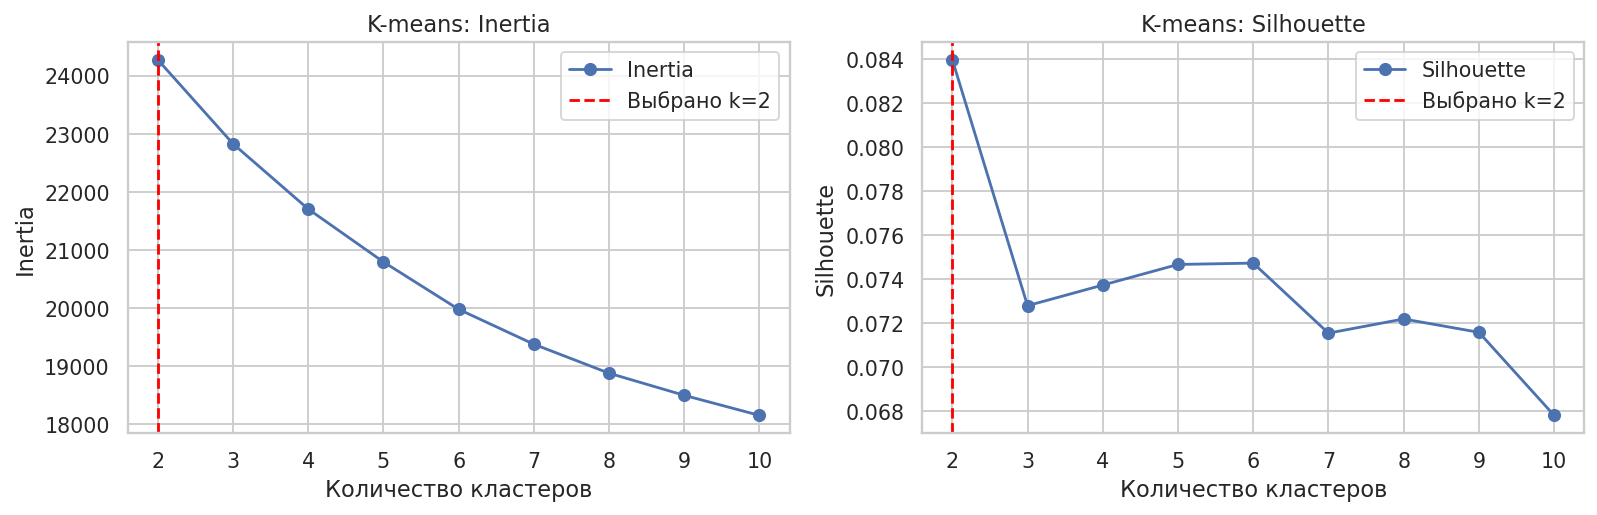

In [9]:
kmeans_models = {}
selection_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    kmeans_models[k] = model
    selection_rows.append({'k': k, 'Inertia': model.inertia_,
                           **cluster_metrics(X, labels)})
selection = pd.DataFrame(selection_rows).set_index('k')
best_k = int(selection['Silhouette'].idxmax())
kmeans = kmeans_models[best_k]
km_labels = kmeans.labels_
display(selection.round(4))
print('Выбранное k по силуэту:', best_k)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ['Inertia', 'Silhouette']):
    ax.plot(selection.index, selection[column], 'o-', label=column)
    ax.axvline(best_k, color='red', linestyle='--', label=f'Выбрано k={best_k}')
    ax.set(xlabel='Количество кластеров', ylabel=column, title=f'K-means: {column}')
    ax.legend()
plt.tight_layout()
plt.show()

### 6–7. Объекты, профили и метрики K-means
Сохраняю метку кластера для каждой строки. groupby.mean даёт средние исходных числовых признаков; средние dummy-столбцов — доли категорий в кластере. Fraud_rate — доля мошеннических транзакций, рассчитанная только после обучения. Она не делает номер кластера предсказанным Fraud. ARI и AMI сравнивают разбиения с поправкой на случайное совпадение и не зависят от перестановки номеров кластеров.

In [10]:
def describe_clusters(labels):
    profile_data = pd.concat([data[numeric_columns], X_categories], axis=1)
    profile_data['Кластер'] = labels
    means = profile_data.groupby('Кластер').mean()
    summary = pd.DataFrame({'Кластер': labels, 'Fraud': y.to_numpy()})
    summary = summary.groupby('Кластер').agg(Размер=('Fraud', 'size'),
                                           Fraud_count=('Fraud', 'sum'),
                                           Fraud_rate=('Fraud', 'mean'))
    return summary, means

km_summary, km_means = describe_clusters(km_labels)
display(km_summary.round(4))
display(km_means.round(3))
assignments = data.copy()
assignments['KMeans_cluster'] = km_labels
display(assignments.head(20))
km_metrics = cluster_metrics(X, km_labels, y)
display(pd.Series(km_metrics, name='K-means').to_frame().round(4))

,Размер,Fraud_count,Fraud_rate
Кластер,,,
0,1514,77,0.0509
1,1510,58,0.0384


,transaction_amount,num_items,time_on_site_sec,hour_of_day,account_age_days,device_type_Desktop,device_type_Mobile,device_type_Tablet,browser_Chrome,browser_Edge,browser_Firefox,browser_Other,browser_Safari,payment_method_BankTransfer,payment_method_COD,payment_method_Card,payment_method_PayPal,country_BR,country_CN,country_DE,country_FR,country_IN,country_Other,country_UK,country_US,is_first_purchase_No,is_first_purchase_Yes,referral_Ads,referral_Direct,referral_Search,referral_Social
Кластер,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,86.653,5.733,164.644,12.324,894.471,0.438,0.491,0.071,0.487,0.112,0.148,0.048,0.204,0.069,0.047,0.595,0.289,0.090,0.089,0.076,0.077,0.120,0.109,0.120,0.320,0.593,0.407,0.103,0.294,0.454,0.149
1,86.731,2.332,165.780,10.441,950.208,0.464,0.460,0.076,0.499,0.102,0.158,0.045,0.197,0.054,0.050,0.617,0.280,0.105,0.095,0.085,0.083,0.112,0.093,0.097,0.331,0.583,0.417,0.103,0.301,0.423,0.173


,transaction_amount,device_type,browser,payment_method,country,num_items,time_on_site_sec,is_first_purchase,referral,hour_of_day,account_age_days,Fraud,KMeans_cluster
0,62.180,Desktop,Safari,COD,UK,3,58.0,No,Direct,15,808,0,1
1,28.160,Desktop,Chrome,COD,US,2,75.0,Yes,Direct,10,753,0,1
2,17.570,Mobile,Chrome,Card,DE,1,101.0,No,Social,21,1017,0,1
3,61.610,Desktop,Safari,PayPal,Other,4,63.0,Yes,Search,20,1146,0,0
4,4.280,Desktop,Edge,Card,BR,7,399.0,No,Direct,4,1134,0,0
5,1.850,Desktop,Firefox,Card,IN,5,307.0,Yes,Search,23,674,0,0
6,12.500,Mobile,Chrome,PayPal,US,4,381.0,No,Search,2,1712,0,1
7,35.300,Desktop,Safari,Card,IN,3,98.0,No,Search,6,1370,0,1
8,81.590,Mobile,Firefox,Card,FR,1,257.0,Yes,Direct,17,1574,0,1
9,46.250,Mobile,Chrome,BankTransfer,IN,5,137.0,No,Search,3,224,0,0


,K-means
Silhouette,0.0840
Calinski_Harabasz,285.5637
Davies_Bouldin,3.2041
ARI,0.0001
AMI,0.0007


### Вывод о кластерах K-means
Кластер 0: 1514 транзакций, в среднем 5,73 товара, доля Fraud 5,09%. Кластер 1: 1510 транзакций, в среднем 2,33 товара, доля Fraud 3,84%. Средние суммы почти одинаковы (86,65 и 86,73 USD); основное различие здесь — размер корзины. В обоих кластерах есть оба класса; выделить мошенничество одним номером кластера нельзя.

### 8. Агломеративная кластеризация и дендрограмма
Использую Ward и евклидово расстояние на той же X. Дендрограмма вычислена на всех строках; для читаемости показаны последние 25 узлов. Число в скобках — количество объектов в свёрнутом узле. По вертикали — расстояние объединения Ward, а не вероятность.

Сравниваю k = 2…10 по силуэту и сопоставляю выбранный разрез с дендрограммой. Пунктир находится между двумя соседними слияниями, соответствующими выбранному числу кластеров. Агломеративная модель не использует Fraud при обучении.

Выбранное число кластеров Ward: 2


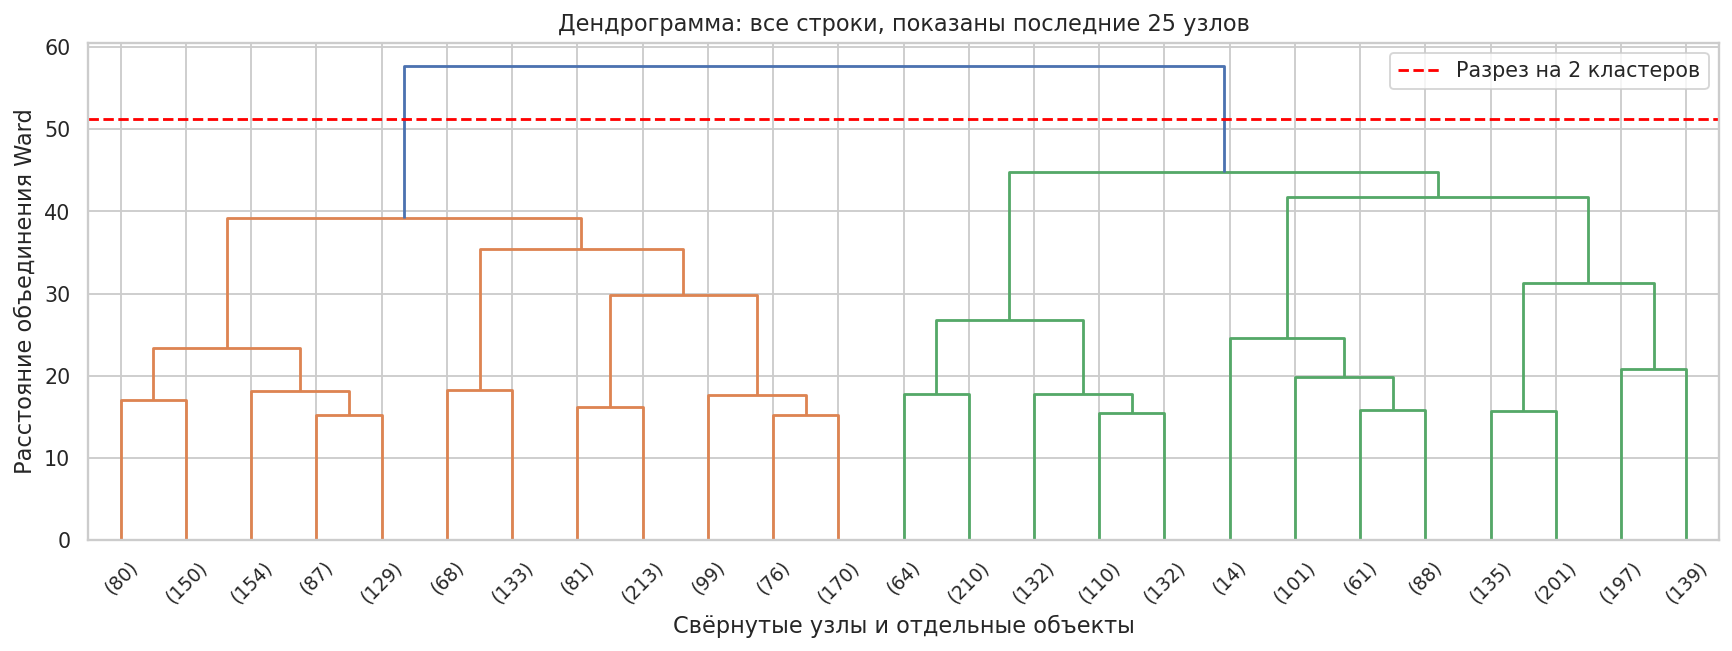

,Silhouette,Calinski_Harabasz,Davies_Bouldin
k,,,
2,0.0604,201.8317,3.8029
3,0.0439,168.6684,3.4717
4,0.0434,154.7773,3.0320
5,0.0384,146.0500,3.2343
6,0.0381,137.7609,3.0191
7,0.0329,129.1108,2.9075
8,0.0288,122.2691,2.8463
9,0.0244,115.4660,2.9689
10,0.0265,109.2299,2.8011


,Размер,Fraud_count,Fraud_rate
Кластер,,,
0,1584,80,0.0505
1,1440,55,0.0382


,transaction_amount,num_items,time_on_site_sec,hour_of_day,account_age_days,device_type_Desktop,device_type_Mobile,device_type_Tablet,browser_Chrome,browser_Edge,browser_Firefox,browser_Other,browser_Safari,payment_method_BankTransfer,payment_method_COD,payment_method_Card,payment_method_PayPal,country_BR,country_CN,country_DE,country_FR,country_IN,country_Other,country_UK,country_US,is_first_purchase_No,is_first_purchase_Yes,referral_Ads,referral_Direct,referral_Search,referral_Social
Кластер,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,81.452,3.949,150.84,6.721,877.603,0.443,0.477,0.080,0.483,0.117,0.156,0.045,0.199,0.059,0.054,0.593,0.293,0.100,0.087,0.084,0.077,0.120,0.098,0.115,0.319,0.561,0.439,0.109,0.313,0.414,0.164
1,92.456,4.129,181.02,16.513,971.472,0.459,0.474,0.067,0.504,0.096,0.149,0.049,0.202,0.063,0.042,0.619,0.276,0.094,0.097,0.076,0.083,0.111,0.103,0.101,0.333,0.617,0.383,0.096,0.281,0.466,0.158


,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI,AMI
K-means,0.0840,285.5637,3.2041,0.0001,0.0007
Ward,0.0604,201.8317,3.8029,-0.0010,0.0006


In [11]:
linked = linkage(X.to_numpy(), method='ward', metric='euclidean')
ag_models = {}
ag_rows = []
for k in range(2, 11):
    model = AgglomerativeClustering(n_clusters=k, linkage='ward', metric='euclidean')
    labels = model.fit_predict(X)
    ag_models[k] = model
    ag_rows.append({'k': k, **cluster_metrics(X, labels)})
ag_selection = pd.DataFrame(ag_rows).set_index('k')
best_ag_k = int(ag_selection['Silhouette'].idxmax())
agglomerative = ag_models[best_ag_k]
ag_labels = agglomerative.labels_
cut_height = (linked[-best_ag_k, 2] + linked[-best_ag_k + 1, 2]) / 2
plt.figure(figsize=(13, 5))
dendrogram(linked, truncate_mode='lastp', p=25, show_leaf_counts=True,
           color_threshold=cut_height)
plt.axhline(cut_height, color='red', linestyle='--', label=f'Разрез на {best_ag_k} кластеров')
plt.xlabel('Свёрнутые узлы и отдельные объекты')
plt.ylabel('Расстояние объединения Ward')
plt.title('Дендрограмма: все строки, показаны последние 25 узлов')
plt.legend()
plt.tight_layout()
plt.show()
display(ag_selection.round(4))
print('Выбранное число кластеров Ward:', best_ag_k)
ag_summary, ag_means = describe_clusters(ag_labels)
display(ag_summary.round(4))
display(ag_means.round(3))
assignments['Ward_cluster'] = ag_labels
ag_metrics = cluster_metrics(X, ag_labels, y)
comparison = pd.DataFrame([km_metrics, ag_metrics], index=['K-means', 'Ward'])
display(comparison.round(4))

### Вывод о кластерах Ward
Кластер 0: 1584 транзакции, средний час покупки 6,72, среднее время на сайте 150,84 с, доля Fraud 5,05%. Кластер 1: 1440 транзакций, средний час 16,51, время на сайте 181,02 с, доля Fraud 3,82%. Ward сильнее разделяет покупки по времени суток. Час рассматривается как линейный признак, поэтому близость 23:00 и 00:00 не учитывается — это ограничение выбранного представления.

### 9. Сравнение и визуализация
На двух парах исходных числовых признаков показываю кластеры K-means и центры (средние координаты групп). Это проекции многомерного разбиения: их пересечение не означает ошибку в 5+dummy измерениях. Затем сравниваю методы и частоты Fraud.

Силуэт и остальные внутренние метрики оценивают компактность, а ARI/AMI — соответствие Fraud. Хорошая компактность не гарантирует обнаружение мошенничества, особенно при редком классе.

K-means — строки: классы, столбцы: кластеры
Ward — строки: классы, столбцы: кластеры


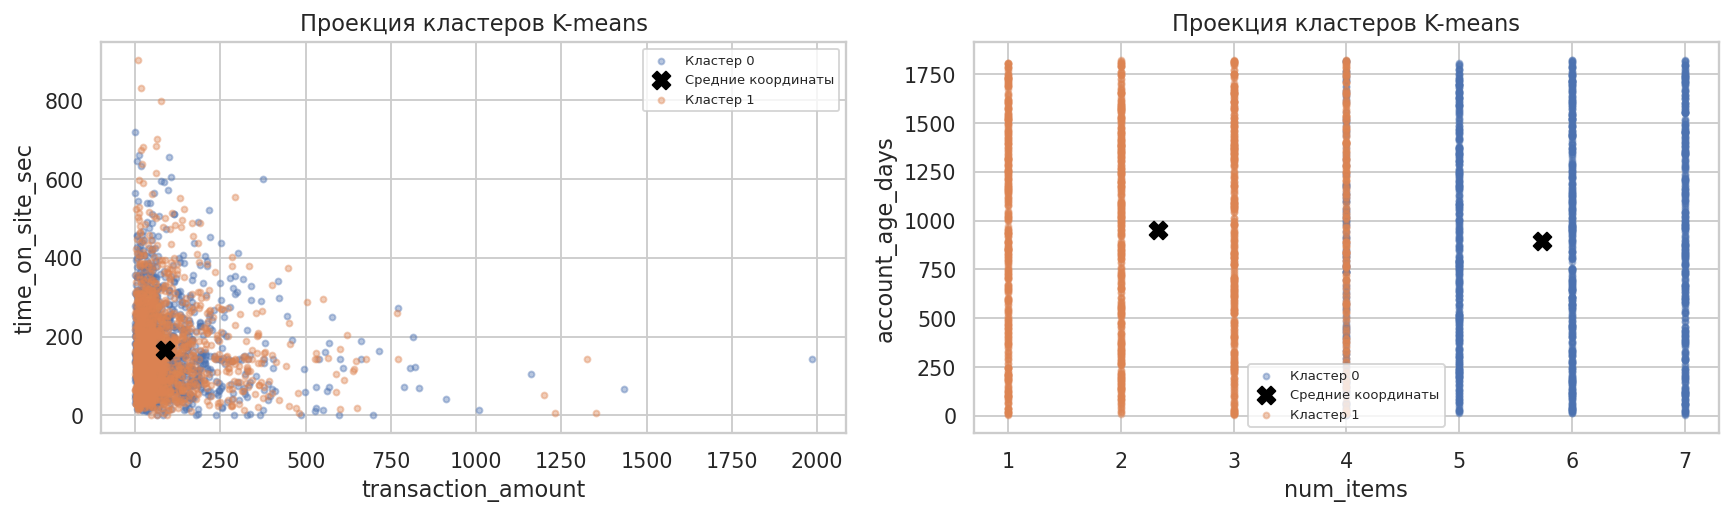

,Кластер 0,Кластер 1
Обычная,1437,1452
Мошенническая,77,58


,Кластер 0,Кластер 1
Обычная,1504,1385
Мошенническая,80,55


In [12]:
pairs = [('transaction_amount', 'time_on_site_sec'), ('num_items', 'account_age_days')]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (first, second) in zip(axes, pairs):
    for cluster in range(best_k):
        points = assignments.loc[km_labels == cluster]
        ax.scatter(points[first], points[second], s=10, alpha=0.4,
                   label=f'Кластер {cluster}')
        ax.scatter(points[first].mean(), points[second].mean(),
                   c='black', marker='X', s=90,
                   label='Средние координаты' if cluster == 0 else None)
    ax.set(xlabel=first, ylabel=second, title='Проекция кластеров K-means')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
for name, labels in [('K-means', km_labels), ('Ward', ag_labels)]:
    table = pd.DataFrame(contingency_matrix(y, labels),
                         index=['Обычная', 'Мошенническая'])
    table.columns = [f'Кластер {i}' for i in range(table.shape[1])]
    print(name, '— строки: классы, столбцы: кластеры')
    display(table)

### Дополнительное сравнение: только числовые признаки
Это проверка влияния прямого кодирования категорий (дополнительный пункт 2). Для честного сравнения отдельно выбираю k в том же диапазоне 2…10. Сравнение силуэта между разными пространствами признаков имеет ограничения; внешние ARI и AMI оцениваются на одних и тех же строках. Остальные дополнительные задания выдаются после защиты и в основной объём не включены.

In [13]:
numeric_models = {}
numeric_scores = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_numeric)
    numeric_models[k] = model
    numeric_scores.append({'k': k, 'Silhouette': silhouette_score(X_numeric, labels)})
numeric_selection = pd.DataFrame(numeric_scores).set_index('k')
numeric_k = int(numeric_selection['Silhouette'].idxmax())
numeric_metrics = cluster_metrics(X_numeric, numeric_models[numeric_k].labels_, y)
encoding_comparison = pd.DataFrame([numeric_metrics, km_metrics],
                                  index=['Числовые признаки', 'Числовые + категории'])
encoding_comparison['k'] = [numeric_k, best_k]
display(encoding_comparison.round(4))

,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI,AMI,k
Числовые признаки,0.1661,426.0810,1.3612,0.0032,0.0253,9
Числовые + категории,0.0840,285.5637,3.2041,0.0001,0.0007,2


## Итог и сохранение результатов
Сравнение выполнено на одном очищенном наборе без использования Fraud в признаках. Число кластеров выбирается внутренним критерием, а не числом известных классов. Выводы ниже формируются по фактически рассчитанным показателям.

Искусственные данные: лучший силуэт среди 2,3,4 кластеров у k=3. Транзакции: исходно 3024, после обработки 3024 строк. K-means: k=2, силуэт=0.0840, ARI=0.0001; Ward: k=2, силуэт=0.0604, ARI=-0.0010. По силуэту предпочтителен K-means. Кластеры описывают сходство транзакций и не являются готовым классификатором мошенничества. Для новых транзакций требуется отдельная проверка обобщения; Ward не имеет обычного predict.

In [14]:
preferred = comparison['Silhouette'].idxmax()
conclusion = (f'Искусственные данные: лучший силуэт среди 2,3,4 кластеров у k='
              f'{int(synthetic_results.loc[synthetic_results.Silhouette.idxmax(), "k"])}. '
              f'Транзакции: исходно {len(raw)}, после обработки {len(data)} строк. '
              f'K-means: k={best_k}, силуэт={km_metrics["Silhouette"]:.4f}, '
              f'ARI={km_metrics["ARI"]:.4f}; Ward: k={best_ag_k}, '
              f'силуэт={ag_metrics["Silhouette"]:.4f}, ARI={ag_metrics["ARI"]:.4f}. '
              f'По силуэту предпочтителен {preferred}. '
              'Кластеры описывают сходство транзакций и не являются готовым '
              'классификатором мошенничества. Для новых транзакций требуется '
              'отдельная проверка обобщения; Ward не имеет обычного predict.')
print(conclusion)
comparison.to_csv('Метрики_ЛР4.csv', encoding='utf-8-sig')
assignments.to_csv('Транзакции_с_кластерами.csv', index=True, index_label='Исходный_индекс',
                   encoding='utf-8-sig')
km_means.to_csv('Профили_KMeans.csv', encoding='utf-8-sig')
ag_means.to_csv('Профили_Ward.csv', encoding='utf-8-sig')

Искусственные данные: лучший силуэт среди 2,3,4 кластеров у k=3. Транзакции: исходно 3024, после обработки 3024 строк. K-means: k=2, силуэт=0.0840, ARI=0.0001; Ward: k=2, силуэт=0.0604, ARI=-0.0010. По силуэту предпочтителен K-means. Кластеры описывают сходство транзакций и не являются готовым классификатором мошенничества. Для новых транзакций требуется отдельная проверка обобщения; Ward не имеет обычного predict.
